In [2]:
import pandas as pd
df2 = pd.read_csv(r"C:\Users\taha2\Downloads\FuelConsumptionCo2.csv")
print(df2.head())
print(df2.columns.tolist())

   MODELYEAR   MAKE       MODEL VEHICLECLASS  ENGINESIZE  CYLINDERS  \
0       2014  ACURA         ILX      COMPACT         2.0          4   
1       2014  ACURA         ILX      COMPACT         2.4          4   
2       2014  ACURA  ILX HYBRID      COMPACT         1.5          4   
3       2014  ACURA     MDX 4WD  SUV - SMALL         3.5          6   
4       2014  ACURA     RDX AWD  SUV - SMALL         3.5          6   

  TRANSMISSION FUELTYPE  FUELCONSUMPTION_CITY  FUELCONSUMPTION_HWY  \
0          AS5        Z                   9.9                  6.7   
1           M6        Z                  11.2                  7.7   
2          AV7        Z                   6.0                  5.8   
3          AS6        Z                  12.7                  9.1   
4          AS6        Z                  12.1                  8.7   

   FUELCONSUMPTION_COMB  FUELCONSUMPTION_COMB_MPG  CO2EMISSIONS  
0                   8.5                        33           196  
1                   

In [3]:
print("Dataset Shape:", df2.shape)

print("Column Names:")
print(df2.columns.tolist())

print("Missing Values:")
print(df2.isnull().sum())

print("Dataset Information:")
df2.info()

Dataset Shape: (1067, 13)
Column Names:
['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'ENGINESIZE', 'CYLINDERS', 'TRANSMISSION', 'FUELTYPE', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB', 'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS']
Missing Values:
MODELYEAR                   0
MAKE                        0
MODEL                       0
VEHICLECLASS                0
ENGINESIZE                  0
CYLINDERS                   0
TRANSMISSION                0
FUELTYPE                    0
FUELCONSUMPTION_CITY        0
FUELCONSUMPTION_HWY         0
FUELCONSUMPTION_COMB        0
FUELCONSUMPTION_COMB_MPG    0
CO2EMISSIONS                0
dtype: int64
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-nu

In [4]:
X = df2[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB']]
y = df2['CO2EMISSIONS']

print("Features (X):")
print(X.head())

print("Target (y):")
print(y.head())

Features (X):
   ENGINESIZE  CYLINDERS  FUELCONSUMPTION_COMB
0         2.0          4                   8.5
1         2.4          4                   9.6
2         1.5          4                   5.9
3         3.5          6                  11.1
4         3.5          6                  10.6
Target (y):
0    196
1    221
2    136
3    255
4    244
Name: CO2EMISSIONS, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (853, 3)
Testing features: (214, 3)
Training target: (853,)
Testing target: (214,)


In [6]:
from sklearn.linear_model import LinearRegression
model2 = LinearRegression()
model2.fit(X_train, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [7]:
y_pred = model2.predict(X_test)
results = pd.DataFrame({
    'Actual CO2': y_test,
    'Predicted CO2': y_pred})

print(results.head(10))

      Actual CO2  Predicted CO2
732          304     302.952377
657          221     240.914900
168          294     272.502441
86           221     235.310180
411          207     204.077026
109          246     245.783073
331          259     304.873201
1003         310     283.650785
566          310     309.171452
327          264     307.729445


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
MAE: 16.72
MSE: 512.86
RMSE: 22.65
R2 Score: 0.876


In [10]:
import matplotlib.pyplot as plt


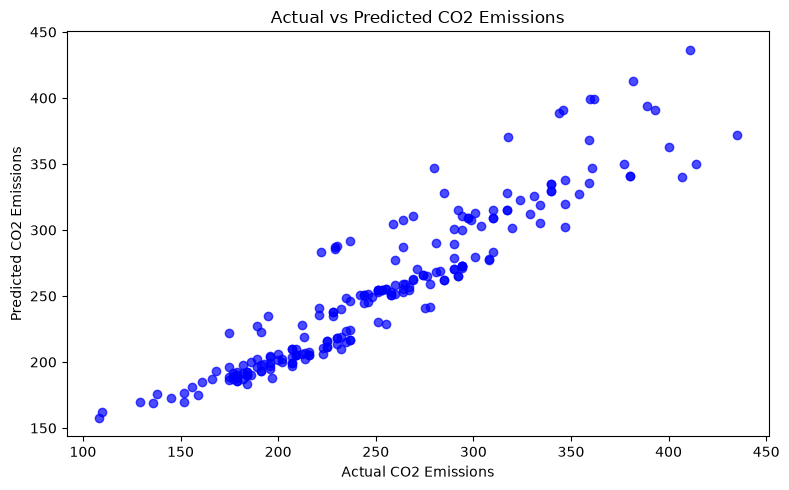

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.xlabel("Actual CO2 Emissions")
plt.ylabel("Predicted CO2 Emissions")
plt.title("Actual vs Predicted CO2 Emissions")
plt.tight_layout()
plt.show()

In [12]:
%pip install gradio


Note: you may need to restart the kernel to use updated packages.


In [13]:
import gradio as gr
import pandas as pd

def predict_co2(engine_size, cylinders, fuel_consumption):
    input_data = pd.DataFrame(
        [[engine_size, cylinders, fuel_consumption]],
        columns=['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB']
    )
    prediction = model2.predict(input_data)[0]
    return round(float(prediction), 2)
demo = gr.Interface(
    fn=predict_co2,
    inputs=[
        gr.Number(label="Engine Size (L)", value=2.0),
        gr.Number(label="Number of Cylinders", value=4),
        gr.Number(label="Combined Fuel Consumption (L/100 km)", value=8.5)
    ],
    outputs=gr.Number(label="Predicted CO2 Emissions"),
    title="Car CO2 Emissions Predictor",
    description="Enter car specifications to predict CO2 emissions."
)
demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


In [2]:
%pip install flask joblib


Note: you may need to restart the kernel to use updated packages.


In [4]:
from sklearn.linear_model import LinearRegression
import joblib

model2 = LinearRegression()
model2.fit(X_train, y_train)

joblib.dump(model2, "co2_model.pkl")

print("CO2 model trained and saved successfully!")

NameError: name 'X_train' is not defined

In [5]:
import os

print(os.path.exists("co2_model.pkl"))

True


In [ ]:
import joblib

joblib.dump(model2, "co2_model.pkl")

print("Dataset 2 model saved successfully!")

In [ ]:
from flask import Flask, request, render_template_string
import pandas as pd
import joblib
import threading
from werkzeug.serving import make_server

# Load Dataset 2 model
co2_model = joblib.load("co2_model.pkl")

app2 = Flask("co2_predictor")

html = """
<h1>Car CO2 Emissions Predictor</h1>
<p>Enter car details to predict CO2 emissions.</p>

<form method="POST">
    <label>Engine Size (L)</label><br>
    <input type="number" name="engine" step="any" required><br><br>

    <label>Number of Cylinders</label><br>
    <input type="number" name="cylinders" step="1" required><br><br>

    <label>Combined Fuel Consumption (L/100 km)</label><br>
    <input type="number" name="fuel" step="any" required><br><br>

    <button type="submit">Predict CO2 Emissions</button>
</form>

{% if prediction is not none %}
    <h2>Predicted CO2 Emissions: {{ prediction }}</h2>
{% endif %}
"""

@app2.route("/", methods=["GET", "POST"])
def home():
    prediction = None

    if request.method == "POST":
        engine = float(request.form["engine"])
        cylinders = int(request.form["cylinders"])
        fuel = float(request.form["fuel"])

        X_new = pd.DataFrame(
            [[engine, cylinders, fuel]],
            columns=[
                "ENGINESIZE",
                "CYLINDERS",
                "FUELCONSUMPTION_COMB"
            ]
        )

        prediction = round(
            float(co2_model.predict(X_new)[0]), 2
        )

    return render_template_string(
        html, prediction=prediction
    )

class NotebookFlaskServer:
    def __init__(self, app, port):
        self.server = make_server("127.0.0.1", port, app)
        self.thread = threading.Thread(
            target=self.server.serve_forever,
            daemon=True
        )

    def start(self):
        self.thread.start()

    def stop(self):
        self.server.shutdown()
        self.thread.join()

server2 = NotebookFlaskServer(app2, 5001)
server2.start()

print("Flask CO2 app is running on port 5001")